## **Federated Learning Across Hospitals: A Comparative Study of Aggregation Methods Under Real Domain Shift Using CNNs on Multi-Hospital Histopathology Data**

# Submission 3: Custom CNN trained from scratch

# Group Information
Name: Sayka Ferdous

ID: 2023-3-60-110

Name: Asrafun Nahar Raisa

ID: 2023-3-60-228

Name: Khaleda Sultana Jamie

ID: 2023-3-60-397

Name: Tahira Tasnim

ID: 2023-3-60-267

### Overview

**Task:** Camelyon17-WILDS (same dataset and same split as Submissions 1 and 2), binary tumor / no-tumor classification of 96×96 lymph-node patches.

| Role | Hospital | Purpose |
|---|---|---|
| Train | 0, 3, 4 | fit the model (future federated clients) |
| Validation | 1 | early stopping and best-weights selection |
| Test | 2 | never seen in training; measures generalisation to a new hospital |

**Model:** a small custom CNN with **no pretrained weights**: four convolutional blocks (2 × [Conv 3×3 → BatchNorm → ReLU], then MaxPool and light dropout), global average pooling, and a fully connected head. About 1.2 M parameters, so it is also small enough to be a client model in the later federated experiments.

**Same data and settings as Submission 2** (same seed, same stratified subsets, same augmentation, same batch size, optimiser, weight decay, label smoothing and cosine learning-rate schedule), so the custom CNN can be compared fairly with the pretrained models.

**Against overfitting:** data augmentation (flips, 90° rotations, colour jitter), BatchNorm, dropout, weight decay, label smoothing, and **early stopping** on validation loss (minimum 5 epochs, patience 7, best weights restored).

**Reported:** accuracy, precision, recall, F1 (per class and macro), AUC, accuracy/loss curves (train vs validation), test confusion matrix, training and testing time.

### 1. Setup and configuration

In [ ]:
import os, json, time, copy, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, roc_auc_score)
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ---- same data settings as Submission 2 (do not change, so the subsets are identical) ----
SEED        = 42
BATCH_SIZE  = 128
IMG_SIZE    = 96
TRAIN_N     = 20000
VAL_N       = 6000
TEST_N      = 20000
CLASS_NAMES = ["No tumor", "Tumor"]

# ---- training settings for the custom CNN ----
MAX_EPOCHS  = 30      # upper limit; early stopping may end training sooner
MIN_EPOCHS  = 5       # early stopping cannot trigger before this epoch (roadmap: minimum 5)
PATIENCE    = 7       # stop if validation loss has not improved for this many epochs
LR          = 1e-3    # from-scratch model: same as the head learning rate in Submission 2
WEIGHT_DECAY = 1e-2

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

# Optional: keep the cached subsets and results on Google Drive so they survive a Colab restart.
USE_DRIVE = True
WORK_DIR = "/content/cse366_submission3"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORK_DIR = "/content/drive/MyDrive/cse366_submission3"
    except Exception as e:
        print("Drive not mounted, using local folder:", e)
RESULTS_DIR = f"{WORK_DIR}/results"; CACHE_DIR = f"{WORK_DIR}/cache"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - switch Runtime > Change runtime type > GPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.14.1+cu130 | device: cuda | Tesla T4


### 2. Download Camelyon17-WILDS

In [ ]:
if not os.path.exists("/content/data/camelyon17_v1.0/metadata.csv"):
    !rm -rf /content/data/camelyon17_v1.0
    !mkdir -p /content/data/camelyon17_v1.0
    !wget --no-check-certificate -O /content/data/camelyon17_v1.0/archive.tar.gz "https://worksheets.codalab.org/rest/bundles/0xe45e15f39fb54e9d9e919556af67aabe/contents/blob/"
    !tar -xzf /content/data/camelyon17_v1.0/archive.tar.gz -C /content/data/camelyon17_v1.0
    !rm /content/data/camelyon17_v1.0/archive.tar.gz
else:
    print("Data already downloaded, skipping.")

!pip install -q wilds
from wilds import get_dataset
dataset = get_dataset(dataset="camelyon17", download=False, root_dir="/content/data")
meta = pd.read_csv("/content/data/camelyon17_v1.0/metadata.csv", index_col=0)
print("Loaded:", dataset, "| metadata:", meta.shape)

Data already downloaded, skipping.
Loaded: <wilds.datasets.camelyon17_dataset.Camelyon17Dataset object at 0x7d79324ae5d0> | metadata: (455954, 8)


### 3. Build the train / validation / test subsets

Identical to Submission 2: subsets are sampled **within each (hospital, class) group** with the same seed, so every hospital keeps its original share, every class stays 50/50, and the **custom CNN sees exactly the same patches as the pretrained models**. Images are decoded once and kept in memory as `uint8` arrays (and cached on disk).

In [ ]:
from concurrent.futures import ThreadPoolExecutor

def stratified_subset(split_name, n):
    idx = np.asarray(dataset.get_subset(split_name).indices)
    df = pd.DataFrame({"idx": idx, "center": meta["center"].values[idx], "tumor": meta["tumor"].values[idx]})
    if n < len(df):
        df = df.groupby(["center", "tumor"], group_keys=False).sample(frac=n / len(df), random_state=SEED)
    return np.random.RandomState(SEED).permutation(df["idx"].values)

def load_images(idx):
    X = np.empty((len(idx), 96, 96, 3), dtype=np.uint8)
    def f(j): X[j] = np.asarray(dataset.get_input(idx[j]).convert("RGB"))
    with ThreadPoolExecutor(16) as ex:
        list(tqdm(ex.map(f, range(len(idx))), total=len(idx), leave=False))
    return X

CACHE_FILE = f"{CACHE_DIR}/subsets_tr{TRAIN_N}_va{VAL_N}_te{TEST_N}_seed{SEED}.npz"
if os.path.exists(CACHE_FILE):
    z = np.load(CACHE_FILE); print("Loaded cached subsets:", CACHE_FILE)
    Xtr_np, ytr_np, ctr = z["Xtr"], z["ytr"], z["ctr"]
    Xva_np, yva_np, cva = z["Xva"], z["yva"], z["cva"]
    Xte_np, yte_np, cte = z["Xte"], z["yte"], z["cte"]
else:
    t0 = time.time(); out = {}
    for key, split, n in [("tr", "train", TRAIN_N), ("va", "val", VAL_N), ("te", "test", TEST_N)]:
        idx = stratified_subset(split, n)
        out["X" + key] = load_images(idx)
        out["y" + key] = meta["tumor"].values[idx].astype(np.int64)
        out["c" + key] = meta["center"].values[idx]
        print(f"{split:5s}: {len(idx):6d} images loaded ({time.time()-t0:.0f}s)")
    np.savez(CACHE_FILE, **out)
    Xtr_np, ytr_np, ctr = out["Xtr"], out["ytr"], out["ctr"]
    Xva_np, yva_np, cva = out["Xva"], out["yva"], out["cva"]
    Xte_np, yte_np, cte = out["Xte"], out["yte"], out["cte"]

summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "hospitals": [sorted(set(ctr)), sorted(set(cva)), sorted(set(cte))],
    "images": [len(ytr_np), len(yva_np), len(yte_np)],
    "no tumor": [(ytr_np == 0).sum(), (yva_np == 0).sum(), (yte_np == 0).sum()],
    "tumor": [(ytr_np == 1).sum(), (yva_np == 1).sum(), (yte_np == 1).sum()],
})
display(summary)
print("Training images per hospital:", {int(h): int(n) for h, n in zip(*np.unique(ctr, return_counts=True))})

Loaded cached subsets: /content/drive/MyDrive/cse366_submission3/cache/subsets_tr20000_va6000_te20000_seed42.npz


,split,hospitals,images,no tumor,tumor
0,train,"[0, 3, 4]",20000,9989,10011
1,validation,[1],6000,3000,3000
2,test,[2],20000,10000,10000


Training images per hospital: {0: 3533, 3: 7734, 4: 8733}


In [ ]:
def to_dev(X): return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(device)
Xtr, Xva, Xte = to_dev(Xtr_np), to_dev(Xva_np), to_dev(Xte_np)
ytr, yva, yte = [torch.from_numpy(y).to(device) for y in (ytr_np, yva_np, yte_np)]
print("Train", tuple(Xtr.shape), "| Val", tuple(Xva.shape), "| Test", tuple(Xte.shape))

Train (20000, 3, 96, 96) | Val (6000, 3, 96, 96) | Test (20000, 3, 96, 96)


### 4. Preprocessing and augmentation (decided in Submission 1, same as Submission 2)

- **Normalisation:** ImageNet mean/std (kept identical to Submission 2 so the comparison is fair; for a from-scratch model it simply centres and scales the inputs).
- **Augmentation (training only):** random horizontal/vertical flips and 90° rotations (tissue has no fixed orientation), plus brightness, contrast, saturation and a small per-channel colour shift to imitate the stain/scanner differences between hospitals. Validation and test images are only normalised.
- Augmentation runs on the GPU, per sample.

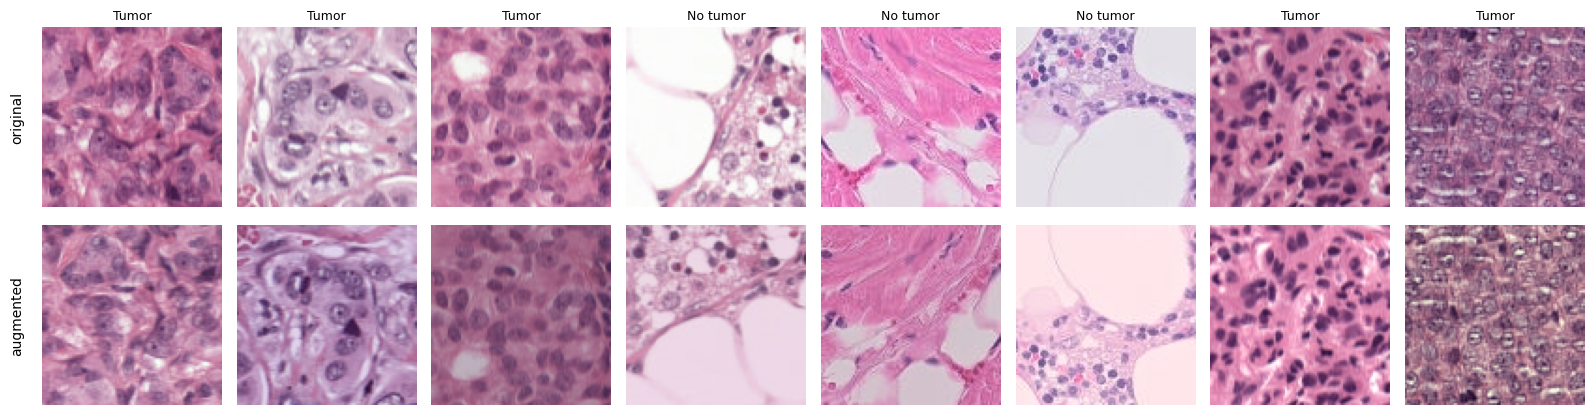

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x):
    n, d = x.shape[0], x.device

    m = torch.rand(n, device=d) < 0.5; x = torch.where(m[:, None, None, None], x.flip(3), x)
    m = torch.rand(n, device=d) < 0.5; x = torch.where(m[:, None, None, None], x.flip(2), x)

    k, out = torch.randint(0, 4, (n,), device=d), x.clone()
    for r in (1, 2, 3):
        sel = k == r
        if sel.any(): out[sel] = torch.rot90(x[sel], r, (2, 3))
    x = out

    u = lambda lo, hi: torch.empty(n, 1, 1, 1, device=d).uniform_(lo, hi)
    x = x * u(0.8, 1.2)                                                     # brightness
    mean = x.mean((1, 2, 3), keepdim=True); x = (x - mean) * u(0.8, 1.2) + mean   # contrast
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]; x = (x - gray) * u(0.8, 1.2) + gray  # saturation
    x = x * torch.empty(n, 3, 1, 1, device=d).uniform_(0.93, 1.07)          # per-channel shift (hue/stain)
    return x.clamp(0, 1)

def prep(xb, train=False):
    x = xb.float().div_(255)
    if x.shape[-1] != IMG_SIZE:
        x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    if train: x = augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


idx = torch.arange(8, device=device)
raw = Xtr[idx].float().div(255); aug = augment(raw.clone())
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for j in range(8):
    for r, im in enumerate((raw, aug)):
        ax[r, j].imshow(im[j].permute(1, 2, 0).cpu().numpy()); ax[r, j].axis("off")
    ax[0, j].set_title(CLASS_NAMES[int(ytr[j])], fontsize=9)
ax[0, 0].text(-0.1, 0.5, "original", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.1, 0.5, "augmented", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

### 5. The custom CNN (trained from scratch)

Design choices, in plain words:

- **Four convolutional blocks** with 32, 64, 128 and 256 filters. Each block has two 3×3 convolutions, each followed by **BatchNorm** (stabilises and speeds up training) and **ReLU**, then **2×2 max-pooling**, which halves the image: 96 → 48 → 24 → 12 → 6. Early blocks learn edges and colour blobs, later blocks learn nuclei shape and tissue texture.
- **Global average pooling** turns the 6×6×256 feature map into 256 numbers. This keeps the parameter count low, which lowers the risk of overfitting on 20,000 training patches.
- **Fully connected head:** Linear(256→128) → ReLU → Dropout(0.4) → Linear(128→2).
- Light **Dropout2d(0.1)** after each block plus weight decay for regularisation.
- Every block has an `attn` slot that is `nn.Identity()` here. Submission 4 will put one attention module (for example SE or CBAM) in that slot and change nothing else.

In [ ]:
class ConvBlock(nn.Module):
    """2 x [Conv3x3 -> BatchNorm -> ReLU] -> (attention slot) -> MaxPool -> Dropout2d."""
    def __init__(self, c_in, c_out, attn=None, p_drop=0.1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(c_in,  c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))
        self.attn = attn if attn is not None else nn.Identity()   # Submission 4: plug an attention module in here
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout2d(p_drop)
    def forward(self, x):
        return self.drop(self.pool(self.attn(self.body(x))))

class CustomCNN(nn.Module):
    def __init__(self, num_classes=2, widths=(32, 64, 128, 256), fc_hidden=128, p_conv=0.1, p_fc=0.4):
        super().__init__()
        chans = (3,) + tuple(widths)
        self.features = nn.Sequential(*[ConvBlock(chans[i], chans[i + 1], p_drop=p_conv) for i in range(len(widths))])
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(widths[-1], fc_hidden), nn.ReLU(inplace=True), nn.Dropout(p_fc),
            nn.Linear(fc_hidden, num_classes))
        for m in self.modules():                       # He initialisation, suited to ReLU
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

_m = CustomCNN()
print(_m)
print(f"\nParameters: total {count_params(_m)[0]:,} | trainable {count_params(_m)[1]:,}")
print("Output shape for one batch:", tuple(_m(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)).shape))
del _m

CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (body): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (attn): Identity()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (drop): Dropout2d(p=0.1, inplace=False)
    )
    (1): ConvBlock(
      (body): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv

### 6. Training code

Same loop as Submission 2, plus **early stopping**:

- Training and validation loss/accuracy are recorded every epoch (loss curves use plain cross-entropy; label smoothing is used only for optimisation).
- Early stopping watches the **validation loss** (hospital 1). Training may stop only after epoch `MIN_EPOCHS` (5), and only when validation loss has not improved for `PATIENCE` (7) epochs. The weights of the best-validation-loss epoch are restored before testing.
- Training time covers all epochs actually run, including the per-epoch validation pass. Testing time is one inference pass over the 20,000 test patches after a warm-up batch.

In [ ]:
@torch.no_grad()
def predict(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(prep(X[i:i + bs])).float())
    return torch.cat(out)

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

CFG_SIG = f"e{MAX_EPOCHS}_tr{TRAIN_N}_va{VAL_N}_te{TEST_N}_s{IMG_SIZE}_seed{SEED}"

def run_experiment(tag_name="custom_cnn"):
    tag = f"{tag_name}_{CFG_SIG}"
    path = f"{RESULTS_DIR}/{tag}.json"
    if os.path.exists(path):
        print(f"[{tag}] found saved result, skipping training.")
        return json.load(open(path))

    set_seed(SEED)
    model = CustomCNN().to(device).to(memory_format=torch.channels_last)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=MAX_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    total_p, train_p = count_params(model)

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_loss": 1e9, "val_acc": 0.0, "epoch": 0, "state": None}
    bad_epochs, stopped_early = 0, False
    n = len(Xtr); steps = n // BATCH_SIZE
    print(f"=== custom CNN from scratch | params {total_p/1e6:.2f}M | max {MAX_EPOCHS} epochs, "
          f"early stopping (min {MIN_EPOCHS}, patience {PATIENCE}) ===")
    sync(); t_fit = time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        run_loss = run_correct = seen = 0
        for s in range(steps):
            b = perm[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]
            x, y = prep(Xtr[b], train=True), ytr[b]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss    += F.cross_entropy(logits.detach().float(), y, reduction="sum").item()
            run_correct += (logits.argmax(1) == y).sum().item(); seen += len(y)
        sched.step()
        vl = predict(model, Xva)
        v_loss = F.cross_entropy(vl, yva).item(); v_acc = (vl.argmax(1) == yva).float().mean().item()
        for k, v in zip(hist, [run_loss / seen, run_correct / seen, v_loss, v_acc]): hist[k].append(v)

        improved = v_loss < best["val_loss"]
        if improved:
            best.update(val_loss=v_loss, val_acc=v_acc, epoch=ep,
                        state={k: t.detach().clone() for k, t in model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1
        print(f"ep {ep:2d}/{MAX_EPOCHS} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} "
              f"| val loss {v_loss:.4f} acc {v_acc:.4f}{'  *best' if improved else ''}")
        if ep >= MIN_EPOCHS and bad_epochs >= PATIENCE:
            stopped_early = True
            print(f"Early stopping at epoch {ep}: validation loss has not improved for {PATIENCE} epochs "
                  f"(best epoch {best['epoch']}).")
            break
    sync(); train_time = time.time() - t_fit
    epochs_run = len(hist["train_loss"])

    model.load_state_dict(best["state"])
    torch.save(best["state"], f"{RESULTS_DIR}/{tag}_best_weights.pt")

    vl = predict(model, Xva); vpred = vl.argmax(1).cpu().numpy()
    v_prf = precision_recall_fscore_support(yva_np, vpred, average="macro", zero_division=0)

    predict(model, Xte[:BATCH_SIZE]); sync(); t0 = time.time()
    logits = predict(model, Xte); sync(); test_time = time.time() - t0
    probs = torch.softmax(logits, 1)[:, 1].cpu().numpy(); pred = logits.argmax(1).cpu().numpy()
    prf = precision_recall_fscore_support(yte_np, pred, average="macro", zero_division=0)

    res = {
        "model": tag_name, "epochs_run": epochs_run, "max_epochs": MAX_EPOCHS, "stopped_early": stopped_early,
        "history": hist, "best_epoch": best["epoch"], "params_total": total_p, "params_trainable": train_p,
        "train_time_s": train_time, "test_time_s": test_time, "n_test": int(len(yte_np)),
        "train_acc_at_best": hist["train_acc"][best["epoch"] - 1],
        "val_acc": float(vl.argmax(1).eq(yva).float().mean().item()), "val_loss": best["val_loss"], "val_f1": float(v_prf[2]),
        "test_acc": float(accuracy_score(yte_np, pred)),
        "test_precision": float(prf[0]), "test_recall": float(prf[1]), "test_f1": float(prf[2]),
        "test_auc": float(roc_auc_score(yte_np, probs)),
        "confusion_matrix": confusion_matrix(yte_np, pred).tolist(),
        "report_text": classification_report(yte_np, pred, target_names=CLASS_NAMES, digits=4),
        "report_dict": classification_report(yte_np, pred, target_names=CLASS_NAMES, output_dict=True),
    }
    json.dump(res, open(path, "w"))
    del model, opt, best; torch.cuda.empty_cache()
    return res

def show_run(res):
    h, be = res["history"], res["best_epoch"]
    ep = np.arange(1, len(h["train_acc"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
    ax[0].plot(ep, h["train_acc"], label="train"); ax[0].plot(ep, h["val_acc"], label="validation (hospital 1)")
    ax[0].axvline(be, ls="--", c="gray", lw=1, label=f"best epoch ({be})")
    ax[0].set(title="Accuracy", xlabel="epoch", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, h["train_loss"], label="train"); ax[1].plot(ep, h["val_loss"], label="validation (hospital 1)")
    ax[1].axvline(be, ls="--", c="gray", lw=1, label=f"best epoch ({be})")
    ax[1].set(title="Loss (cross-entropy)", xlabel="epoch", ylabel="loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    cm = np.array(res["confusion_matrix"]); cmn = cm / cm.sum(1, keepdims=True)
    ax[2].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax[2].text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                       color="white" if cmn[i, j] > .5 else "black")
    ax[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
              xlabel="predicted", ylabel="true", title="Confusion matrix (test, hospital 2)")
    fig.suptitle("Custom CNN from scratch", fontweight="bold")
    plt.tight_layout(); plt.show()
    print(f"Classification report - test hospital 2 ({res['n_test']} patches)\n{res['report_text']}")
    print(f"Accuracy {res['test_acc']:.4f} | AUC {res['test_auc']:.4f} | epochs run {res['epochs_run']}/{res['max_epochs']} "
          f"(best epoch {be}, early stopped: {res['stopped_early']})")
    print(f"Training time {res['train_time_s']/60:.1f} min | testing time {res['test_time_s']:.2f} s "
          f"({res['n_test']/res['test_time_s']:.0f} images/s)")

### 7. Train and evaluate

[custom_cnn_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


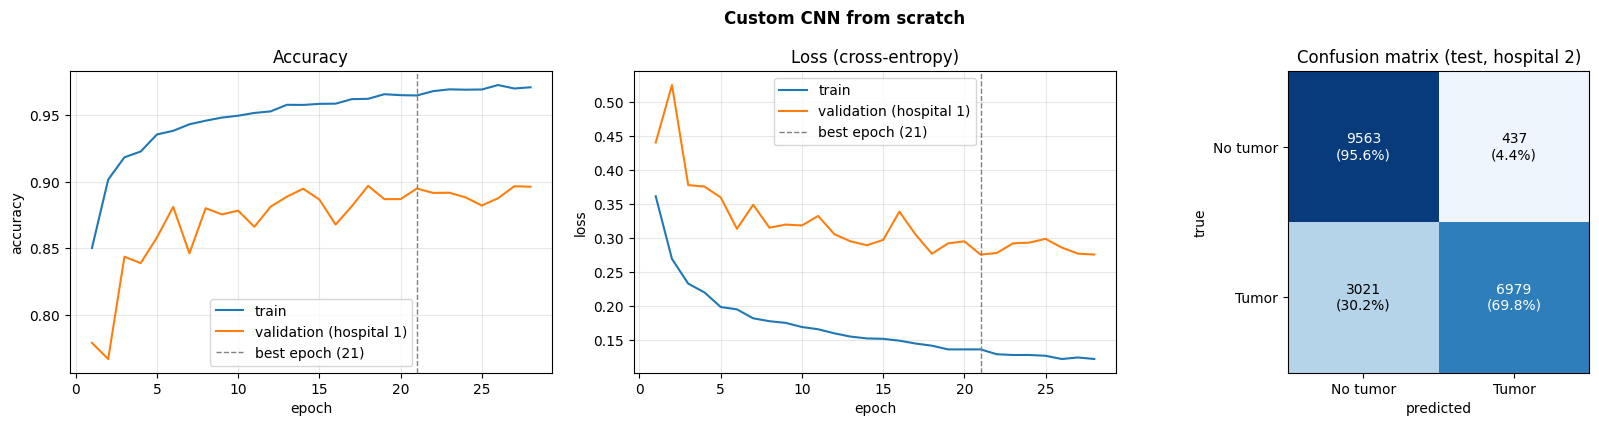

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.7599    0.9563    0.8469     10000
       Tumor     0.9411    0.6979    0.8014     10000

    accuracy                         0.8271     20000
   macro avg     0.8505    0.8271    0.8242     20000
weighted avg     0.8505    0.8271    0.8242     20000

Accuracy 0.8271 | AUC 0.8947 | epochs run 28/30 (best epoch 21, early stopped: True)
Training time 4.3 min | testing time 2.73 s (7327 images/s)


In [ ]:
res = run_experiment("custom_cnn")
show_run(res)

### 8. Comparison with the pretrained models of Submission 2

The Submission 2 numbers below are copied from our Submission 2 report (same data, same test hospital 2). Training time is not directly comparable in terms of epochs because early stopping may end the custom CNN earlier.

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC,Train time (min),Test time (s),Params (M)
0,Custom CNN (scratch),0.8271,0.8505,0.8271,0.8242,0.8947,4.3,2.73,1.206
1,ResNet-50 (frozen),0.8621,0.8652,0.8621,0.8619,0.9359,3.1,4.30,0.004
2,ResNet-50 (fine-tuned),0.9235,0.9314,0.9235,0.9232,0.9775,7.5,4.24,23.510
3,DenseNet-121 (frozen),0.8868,0.8879,0.8868,0.8867,0.9519,4.1,5.90,0.002
4,DenseNet-121 (fine-tuned),0.9087,0.9180,0.9087,0.9082,0.9694,9.6,5.84,6.960
5,EfficientNet-B0 (frozen),0.8912,0.8930,0.8912,0.8911,0.9561,1.9,2.40,0.003
6,EfficientNet-B0 (fine-tuned),0.8914,0.9059,0.8914,0.8904,0.9625,5.4,2.29,4.010


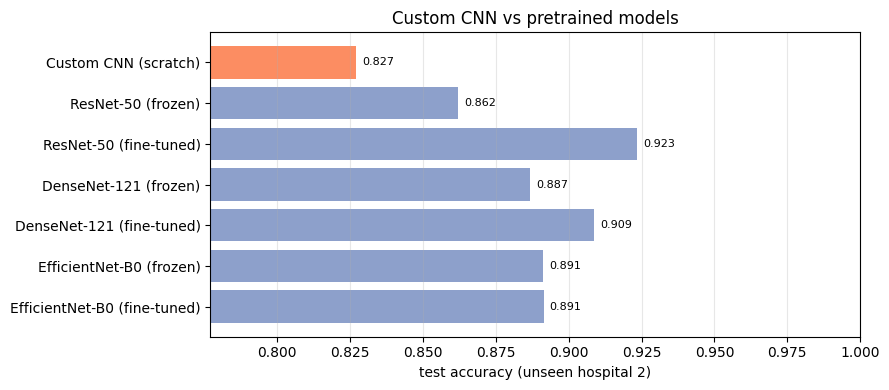

In [ ]:
sub2 = pd.DataFrame([
    # model, accuracy, precision, recall, f1, auc, train_min, test_s
    ("ResNet-50 (frozen)",            0.8621, 0.8652, 0.8621, 0.8619, 0.9359, 3.1, 4.30),
    ("ResNet-50 (fine-tuned)",        0.9235, 0.9314, 0.9235, 0.9232, 0.9775, 7.5, 4.24),
    ("DenseNet-121 (frozen)",         0.8868, 0.8879, 0.8868, 0.8867, 0.9519, 4.1, 5.90),
    ("DenseNet-121 (fine-tuned)",     0.9087, 0.9180, 0.9087, 0.9082, 0.9694, 9.6, 5.84),
    ("EfficientNet-B0 (frozen)",      0.8912, 0.8930, 0.8912, 0.8911, 0.9561, 1.9, 2.40),
    ("EfficientNet-B0 (fine-tuned)",  0.8914, 0.9059, 0.8914, 0.8904, 0.9625, 5.4, 2.29),
], columns=["Model", "Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "AUC", "Train time (min)", "Test time (s)"])
sub2["Params (M)"] = [0.004, 23.51, 0.002, 6.96, 0.003, 4.01]   # trainable parameters, from the Submission 2 report

custom = pd.DataFrame([("Custom CNN (scratch)", res["test_acc"], res["test_precision"], res["test_recall"],
                        res["test_f1"], res["test_auc"], res["train_time_s"] / 60, res["test_time_s"],
                        res["params_trainable"] / 1e6)], columns=sub2.columns)
cmp_df = pd.concat([custom, sub2], ignore_index=True)
cmp_df.to_csv(f"{WORK_DIR}/submission3_comparison.csv", index=False)
display(cmp_df.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "AUC"]}
                            | {"Train time (min)": "{:.1f}", "Test time (s)": "{:.2f}", "Params (M)": "{:.3f}"})
        .background_gradient(subset=["Accuracy", "F1 (macro)"], cmap="Greens"))

fig, a = plt.subplots(figsize=(9, 4))
a.barh(cmp_df["Model"][::-1], cmp_df["Accuracy"][::-1], color=["#8da0cb"] * 6 + ["#fc8d62"])
for i, v in enumerate(cmp_df["Accuracy"][::-1]): a.text(v + .002, i, f"{v:.3f}", va="center", fontsize=8)
a.set(xlim=(max(0.5, cmp_df["Accuracy"].min() - 0.05), 1.0), xlabel="test accuracy (unseen hospital 2)", title="Custom CNN vs pretrained models")
a.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

### 9. Over/underfitting diagnostics

Same rules as Submission 2: **overfitting** if train accuracy exceeds validation accuracy by more than 10 points at the best epoch, or if validation loss at the last epoch is more than 15% above its minimum; **underfitting** if train accuracy at the best epoch is below 85%; **domain-shift gap** if validation (hospital 1) accuracy is more than 5 points above test (hospital 2) accuracy.

In [ ]:
h = res["history"]
tr, va, te = res["train_acc_at_best"], res["val_acc"], res["test_acc"]
vmin, vlast = min(h["val_loss"]), h["val_loss"][-1]
flags = []
if tr - va > 0.10 or vlast > 1.15 * vmin: flags.append("OVERFITTING")
if tr < 0.85: flags.append("underfitting")
if va - te > 0.05: flags.append("domain-shift gap")
print(f"train acc {tr:.3f} | val acc {va:.3f} | test acc {te:.3f}")
print(f"gap train-val {tr-va:+.3f} | gap val-test {va-te:+.3f} | last val loss / min val loss = {vlast/vmin:.2f}")
print("Verdict:", ", ".join(flags) or "ok")
print(f"Epochs run: {res['epochs_run']} of {res['max_epochs']} (best epoch {res['best_epoch']}, early stopped: {res['stopped_early']})")

train acc 0.965 | val acc 0.895 | test acc 0.827
gap train-val +0.070 | gap val-test +0.068 | last val loss / min val loss = 1.00
Verdict: domain-shift gap
Epochs run: 28 of 30 (best epoch 21, early stopped: True)


### 10. Findings

**Performance.** The custom CNN trained from scratch reached 82.71% accuracy, macro-F1 0.8242 and AUC 0.8947 on the unseen test hospital 2 (20,000 patches), with 1.21 M parameters.

**Comparison with pretrained models.** This is lower than all six pretrained runs of Submission 2: the weakest of them, ResNet-50 with a frozen backbone, reached 86.21% accuracy and 0.9359 AUC, and the best, ResNet-50 fine-tuned, reached 92.35% and 0.9775. The gap to the best model is 9.6 points of accuracy. The custom CNN has no ImageNet features and only 20,000 training patches, which is a plausible reason; we have not tested this. It is, however, higher than the 70.3% that the WILDS paper reports for a DenseNet-121 trained from scratch on this hospital, although the settings differ (training subset, augmentation, single seed), so we do not claim the two are directly comparable.

**Overfitting and early stopping.** Training stopped at epoch 28 of 30 because validation loss had not improved for 7 epochs; the best epoch was 21 (validation loss 0.2758, validation accuracy 89.5%). Training accuracy at the best epoch was 96.5% (measured on augmented batches), a train-validation gap of 7.0 points, and the final validation loss was equal to its minimum, so none of our overfitting thresholds was met and the model did not underfit. Because early stopping triggered only two epochs before the 30-epoch limit and the cosine learning-rate schedule had almost finished, it saved little training time; the main protection was restoring the best-validation-loss weights before testing.

**Error pattern.** On hospital 2 the model clears 95.6% of tumor-free patches (437 false alarms) and is precise when it flags tumor (precision 0.941), but it misses 3,021 of 10,000 tumor patches (tumor recall 0.698). This is the lowest tumor recall of all runs so far (the six pretrained runs ranged from 0.797 to 0.914). In a diagnostic setting missed tumors are the costlier error, so this is the main weakness. We have not tested the cause; a shift in stain or scanner appearance at the new hospital is a plausible explanation.

**Validation versus test.** Validation accuracy on hospital 1 was 89.5% against 82.7% on hospital 2, a difference of 6.8 points. This is larger than for the fine-tuned pretrained models (0.5 to 4.8 points) and is the only flag raised by our diagnostic rules ("domain-shift gap"). It suggests that selecting the best epoch on one hospital does not guarantee the same performance on another, and that the from-scratch model may be more sensitive to hospital-level shift than the pretrained ones; this needs further testing.

**Cost.** Training took 4.3 min for 28 epochs and testing took 2.73 s for 20,000 patches (about 7,300 patches per second), similar to the pretrained models.

**Limitations.** One random seed, data subsets (20,000 train / 6,000 validation / 20,000 test patches), and a single unseen test hospital, so small differences should not be over-interpreted.

**Implication for later submissions.** This model is the baseline for Submission 4, where one attention module will be added with everything else unchanged. Because it is small (about 1.2 M parameters) it is also a candidate client model for the federated stage, where the hospital-level shift seen here will be central.

**Reference:** Koh et al., "WILDS: A Benchmark of in-the-Wild Distribution Shifts", ICML 2021 (https://arxiv.org/abs/2012.07421).